# Hadi AlHajji - 2230000809

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [7]:
from pathlib import Path
# pandas is already imported as pd in Step 1.

# Dataset location
dataset_path = Path("dataset/Lab_11_QnA_Dataset.csv")

# Check if file exists
print("File exists:", dataset_path.exists())

# Load dataset
df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

File exists: True
Dataset loaded successfully!
Shape: (168, 3)


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [8]:
import re
# Lowercase and remove punctuation; keep tokens aligned with displayed words.
df['question'] = df['question'].astype(str).str.lower().apply(
    lambda s: re.sub(r'[^\w\s]', '', s).strip())
df = df[df['question'].str.len() > 0].reset_index(drop=True)
from collections import Counter
vocab = {'<PAD>': 0, '<UNK>': 1}
for question in df['question']:
    for word in question.split():
        if word not in vocab:
            vocab[word] = len(vocab)
sequences = [[vocab[w] for w in q.split()] for q in df['question']]
max_len = max(map(len, sequences))
X = torch.tensor([seq + [0] * (max_len - len(seq)) for seq in sequences], dtype=torch.long)
label_codes, label_names = pd.factorize(df['answer_id'])
y = torch.tensor(label_codes, dtype=torch.long)
print('Vocabulary:', len(vocab), '| Max length:', max_len, '| Classes:', len(label_names))

Vocabulary: 228 | Max length: 11 | Classes: 12


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [9]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(vocab), 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, len(label_names))

    def forward(self, x):
        outputs, _ = self.rnn(self.emb(x))  # [batch, words, hidden]
        scores = self.att(outputs).squeeze(-1)
        scores = scores.masked_fill(x == 0, -1e9)  # Ignore padding
        weights = torch.softmax(scores, dim=1)
        context = (outputs * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [10]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
model.train()
for epoch in range(50):
    optimizer.zero_grad()  # Clear gradients from the previous step
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()
    if (epoch + 1) % 10 == 0:
        accuracy = (logits.argmax(dim=1) == y).float().mean().item()
        print(f'Epoch {epoch + 1:2d} | loss={loss.item():.4f} | train accuracy={accuracy:.1%}')
model.eval()
print('Training finished!')

Epoch 10 | loss=1.8328 | train accuracy=50.6%
Epoch 20 | loss=0.9532 | train accuracy=76.2%
Epoch 30 | loss=0.3626 | train accuracy=93.5%
Epoch 40 | loss=0.1231 | train accuracy=97.0%
Epoch 50 | loss=0.0484 | train accuracy=98.8%
Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

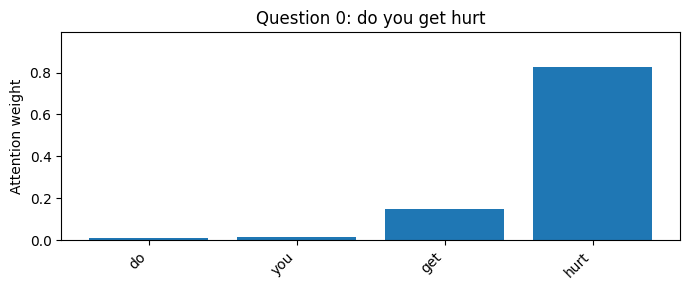

Highest-attention word: 'hurt' (0.827); predicted answer ID: 0


In [11]:
def show_attention(index, ax=None):
    words = df.loc[index, 'question'].split()
    with torch.no_grad():
        logits, attention = model(X[index:index+1])
    values = attention[0, :len(words)].cpu().numpy()
    if ax is None:
        _, ax = plt.subplots(figsize=(max(7, len(words) * 0.65), 3))
    ax.bar(range(len(words)), values)
    ax.set_xticks(range(len(words)), words, rotation=45, ha='right')
    ax.set_title(f'Question {index}: {df.loc[index, "question"]}')
    ax.set_ylabel('Attention weight')
    ax.set_ylim(0, max(0.2, float(values.max()) * 1.2))
    return words[int(values.argmax())], float(values.max()), label_names[int(logits.argmax(dim=1).item())]

word, weight, answer = show_attention(0)
plt.tight_layout()
plt.show()
print(f'Highest-attention word: {word!r} ({weight:.3f}); predicted answer ID: {answer}')

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

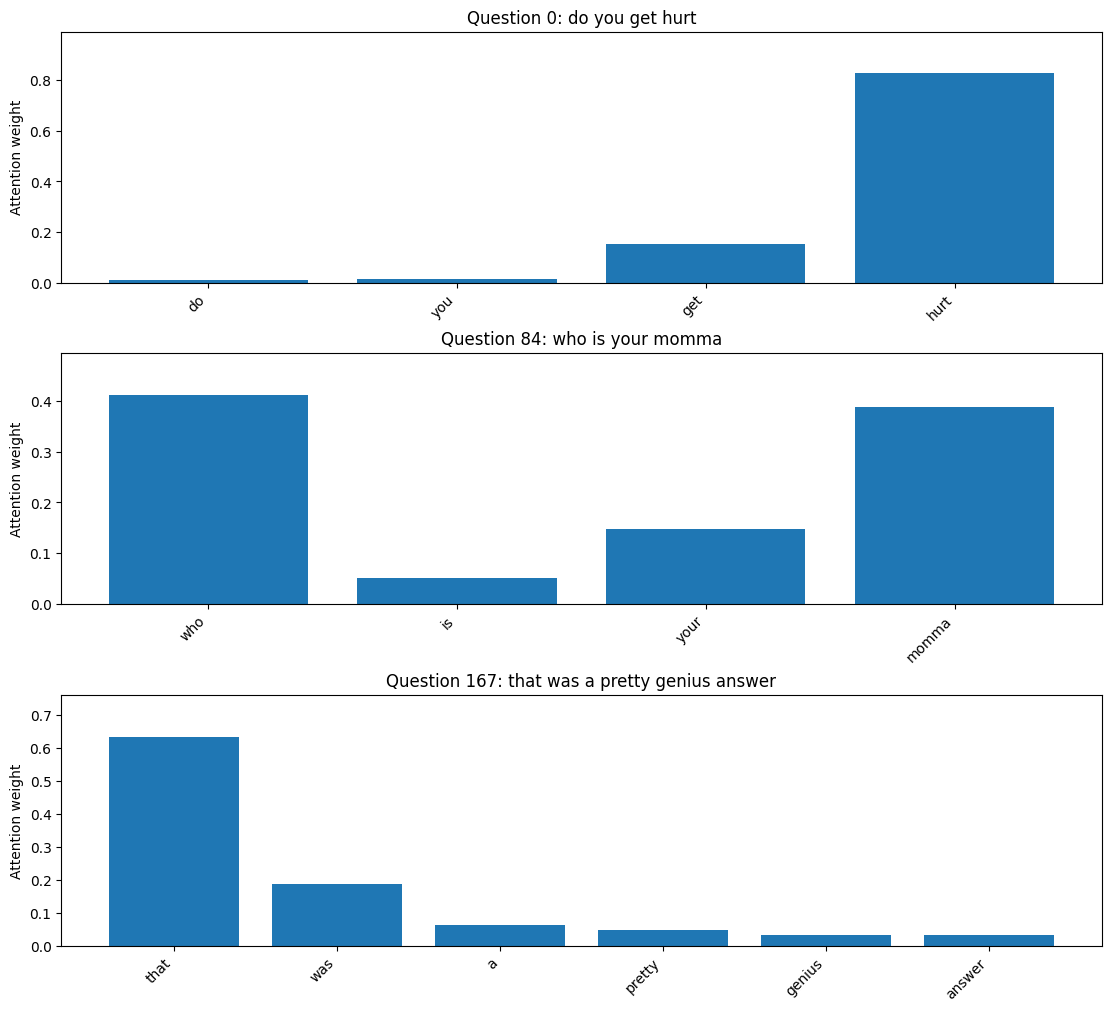

Question 0: do you get hurt
  Highest attention: 'hurt' (0.827); predicted answer ID: 0
Question 84: who is your momma
  Highest attention: 'who' (0.412); predicted answer ID: 6
Question 167: that was a pretty genius answer
  Highest attention: 'that' (0.634); predicted answer ID: 11
Review the attention plots and compare the highest-weight words; attention is not proof of causality.


In [12]:
# Task 1: Plot three distinct questions and report their top-attended words.
indices = list(dict.fromkeys([0, len(df)//2, len(df)-1]))
if len(indices) < 3:
    raise ValueError('Task 1 needs at least three questions.')
fig, axes = plt.subplots(3, 1, figsize=(11, 10), constrained_layout=True)
results = []
for idx, ax in zip(indices, axes):
    top_word, top_weight, predicted_id = show_attention(idx, ax)
    results.append((idx, top_word, top_weight, predicted_id))
plt.show()
for idx, word, weight, pred in results:
    print(f'Question {idx}: {df.loc[idx, "question"]}')
    print(f'  Highest attention: {word!r} ({weight:.3f}); predicted answer ID: {pred}')

print("Review the attention plots and compare the highest-weight words; attention is not proof of causality.")

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question 120: what do you like to be called
  True answer ID: 8; predicted: 8
  Highest-attention word: 'be' (weight 0.433)
Question 124: so what do you like to be called
  True answer ID: 8; predicted: 8
  Highest-attention word: 'so' (weight 0.755)


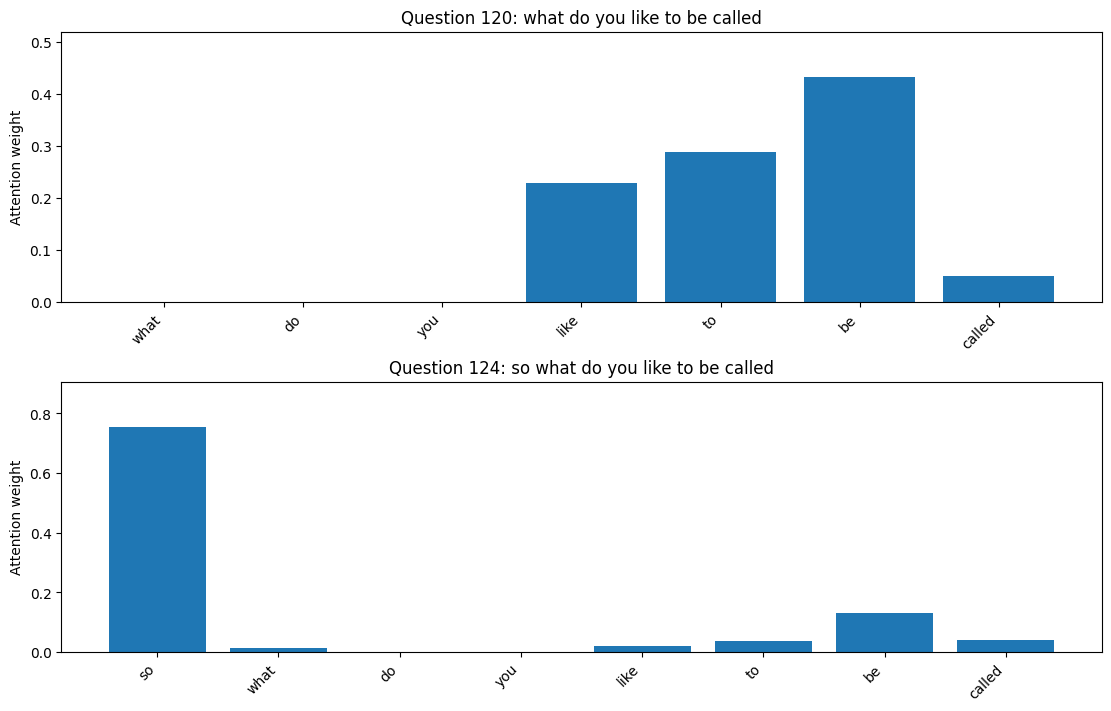

Pair TF-IDF similarity: 0.905
Review the attention plots and compare the highest-weight words; attention is not proof of causality.


In [13]:
# Task 2: Find two differently worded questions with the same answer ID.
# Prefer a pair with high TF-IDF cosine similarity, so the meaning is likely similar.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vectorizer = TfidfVectorizer(ngram_range=(1, 2))
features = vectorizer.fit_transform(df['question'])
labels = df['answer_id'].astype(str).to_numpy()
questions = df['question'].to_numpy()
chosen = None
best_score = -1.0
for label in pd.unique(labels):
    ids = np.where(labels == label)[0]
    if len(ids) < 2:
        continue
    similarities = cosine_similarity(features[ids])
    np.fill_diagonal(similarities, -1)
    for a in range(len(ids)):
        for b in range(a+1, len(ids)):
            if questions[ids[a]] != questions[ids[b]] and similarities[a,b] > best_score:
                chosen = (int(ids[a]), int(ids[b]))
                best_score = float(similarities[a,b])
if chosen is None:
    raise ValueError('No differently worded questions sharing an answer ID were found. Select a pair manually.')

fig, axes = plt.subplots(2, 1, figsize=(11, 7), constrained_layout=True)
for idx, ax in zip(chosen, axes):
    top_word, top_weight, predicted_id = show_attention(idx, ax)
    print(f'Question {idx}: {df.loc[idx, "question"]}')
    print(f'  True answer ID: {df.loc[idx, "answer_id"]}; predicted: {predicted_id}')
    print(f'  Highest-attention word: {top_word!r} (weight {top_weight:.3f})')
plt.show()
print(f'Pair TF-IDF similarity: {best_score:.3f}')
print("Review the attention plots and compare the highest-weight words; attention is not proof of causality.")

# hadi AlHajji - 2230000809